In [351]:
# Setup

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

# To make project modules importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# dataset's path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-churn.csv"

print(DATA_PATH)
print(DATA_PATH.exists())

/Users/priyankamanoj/UniversityCourseWork/Verizon/telco_churn_pipeline/data/raw/Telco-churn.csv
True


In [111]:
import sys
import numpy as np
import pandas as pd
import sklearn

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: /Users/priyankamanoj/UniversityCourseWork/Verizon/telco_churn_pipeline/.venv/bin/python
NumPy: 2.3.5
Pandas: 2.3.3
Scikit-learn: 1.9.1


In [352]:
print(str(PROJECT_ROOT) in sys.path)

True


In [353]:
print(Path.cwd())

/Users/priyankamanoj/UniversityCourseWork/Verizon/telco_churn_pipeline/notebooks


In [114]:
%reload_ext autoreload
%autoreload 2

In [354]:
%reload_ext jupyter_black

from steps.data_ingestion import load_and_split_data

from steps.preprocessing import TotalChargesCleaner, CatBoostPreprocessor

from steps.preprocessing import build_lr_preprocessor, build_tree_preprocessor

from steps.model_training import (
    build_lr_pipeline,
    build_rf_pipeline,
    build_gb_pipeline,
    build_catboost_pipeline,
    build_svm_pipeline,
)

from steps.feature_engineering import (
    build_lr_feature_pipeline,
)


from steps.evaluation import (
    cross_validate_model,
    evaluate_model,
    plot_confusion_matrix,
    calculate_ece,
)
from steps.risk_stratification import assign_risk_tier

import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

import joblib

In [116]:
X_train, X_val, X_test, y_train, y_val, y_test = load_and_split_data(DATA_PATH)

In [117]:
X_train.shape, X_val.shape, X_test.shape

((4930, 19), (1056, 19), (1057, 19))

In [118]:
y_train.shape, y_val.shape, y_test.shape

((4930,), (1056,), (1057,))

> Data splitting is successfully done. 

> Verifying if the preprocessor works correctly.

In [119]:
cleaner = TotalChargesCleaner()
X_train_clean = cleaner.fit_transform(X_train)
X_train_clean.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

In [120]:
print(X_train_clean["TotalCharges"].dtype)

float64


> The total charges column has been cleaned successfully.  
> NOTE: TotalChargesCleaner needs to run before column transformer

In [121]:
X_train_clean.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

## Let's get the list of numerical and categorical features

In [122]:
num_features = ["tenure", "MonthlyCharges", "TotalCharges"]

In [123]:
cat_features = [col for col in X_train.columns if col not in num_features]
cat_features

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [124]:
print("Numerical:", len(num_features))
print("Categorical:", len(cat_features))

assert len(num_features) + len(cat_features) == X_train.shape[1]

Numerical: 3
Categorical: 16


# Logistic Regression 

In [125]:
# Step 1 : Instantiate the preprocessor
preprocessor = build_lr_preprocessor(num_features, cat_features)

In [126]:
# Step 2 : Clean TotalCharges

X_train_clean = TotalChargesCleaner().fit_transform(X_train)

In [127]:
# Step 3: Preprocess the cleaned train set

X_train_processed = preprocessor.fit_transform(X_train_clean)

print(X_train_processed.shape)

(4930, 46)


In [128]:
# Validate the processed train set
print(X_train_clean.dtypes)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [129]:
# build the pipeline

lr_pipeline = build_lr_pipeline(num_features, cat_features)

lr_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [130]:
# Step 5: Let's do cross validation and check cv

lr_cv_results = cross_validate_model(lr_pipeline, X_train, y_train)

display(lr_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.809,0.668,0.560,0.608,0.845
std,0.011,0.027,0.049,0.029,0.010


In [131]:
# Step 6: Check Validation performance

lr_val_results = evaluate_model(lr_pipeline, X_val, y_val)

display(lr_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.835     0.881     0.858       776
       Churn      0.612     0.518     0.561       280

    accuracy                          0.785      1056
   macro avg      0.723     0.700     0.709      1056
weighted avg      0.776     0.785     0.779      1056



Accuracy     0.785
Precision    0.612
Recall       0.518
F1           0.561
ROC-AUC      0.842
dtype: float64

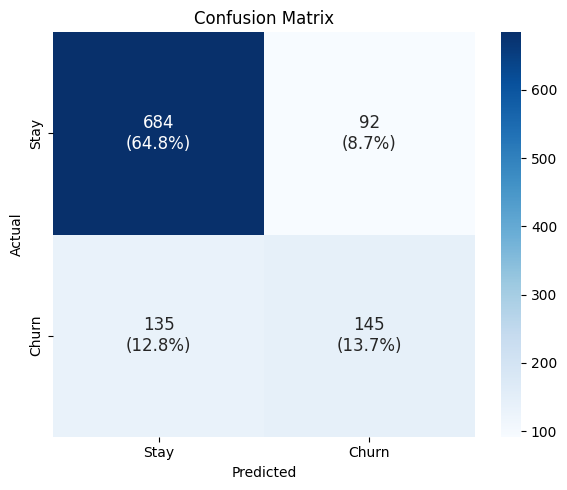

In [132]:
plot_confusion_matrix(lr_pipeline, X_val, y_val)

Metric	Score	Interpretation
---
* Accuracy	78.5%:	Correct predictions overall
* Churn precision	61.2%:	Of customers flagged as likely to churn, 61.2% actually churned
* Churn recall	51.8%:	The model identified only 51.8% of actual churners
* Churn F1	56.1%:	Balance between churn precision and recall
* Specificity	88.1%:	Correctly identified customers who stayed

Almost half the churners missed in the validation set. 

NOTES
---

I want to cast a wider net and catch the churners. But I do not want to waste resources on wrongly flagged customers. So, we shall optimise the model for Recall (the wider net) while keeping a tab on F1-score so that we precision and recall are balanced. 


> We are dealing with a moderately imbalanced dataset. Let's check if the Recall and F1-score improves with class weights. 

In [133]:
# balanced logistic regression

lr_balanced = build_lr_pipeline(num_features, cat_features, class_weight="balanced")

In [134]:
lr_balanced.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [135]:
# Let's get the cv performance

lr_balanced_cv_results = cross_validate_model(lr_balanced, X_train, y_train)
display(lr_balanced_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.748,0.516,0.806,0.629,0.845
std,0.013,0.016,0.028,0.016,0.010


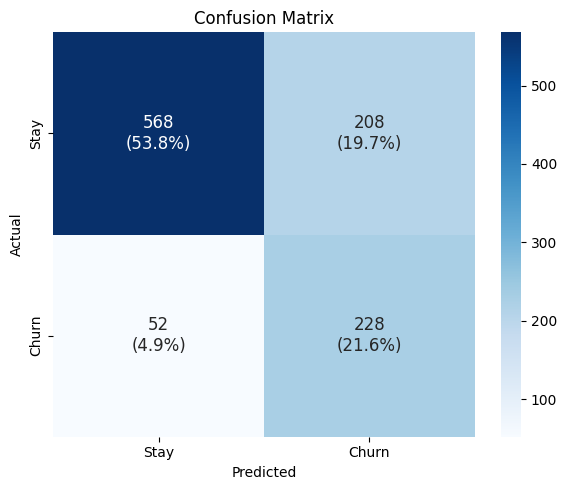

In [136]:
plot_confusion_matrix(lr_balanced, X_val, y_val)

In [137]:
lr_balanced_val_results = evaluate_model(lr_balanced, X_val, y_val)
display(lr_balanced_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.916     0.732     0.814       776
       Churn      0.523     0.814     0.637       280

    accuracy                          0.754      1056
   macro avg      0.720     0.773     0.725      1056
weighted avg      0.812     0.754     0.767      1056



Accuracy     0.754
Precision    0.523
Recall       0.814
F1           0.637
ROC-AUC      0.843
dtype: float64

NOTE
---

> After weighting the model, Recall jumped to 81%, that's an improvement of 29 points. ROC-AUC remained unchanged at 84%, which means the model can distinguish both the classes very well with or without weights. The precision has dropped 10 points, this is expected since we are optimising the model for Recall.

### RECALL : 81%, F1 : 63.8%, ROC-AUC: 0.845 shall be our baseline.

# Random Forest Classifier

In [138]:
# Let's test the model without weights

In [139]:
rf_pipeline = build_rf_pipeline(num_features, cat_features)
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [140]:
# Let's get the CV results

rf_cv_results = cross_validate_model(rf_pipeline, X_train, y_train)
display(rf_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.791,0.639,0.492,0.555,0.820
std,0.010,0.031,0.037,0.024,0.007


In [141]:
rf_val_results = evaluate_model(rf_pipeline, X_val, y_val)
display(rf_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.826     0.889     0.857       776
       Churn      0.611     0.482     0.539       280

    accuracy                          0.781      1056
   macro avg      0.719     0.686     0.698      1056
weighted avg      0.769     0.781     0.772      1056



Accuracy     0.781
Precision    0.611
Recall       0.482
F1           0.539
ROC-AUC      0.825
dtype: float64

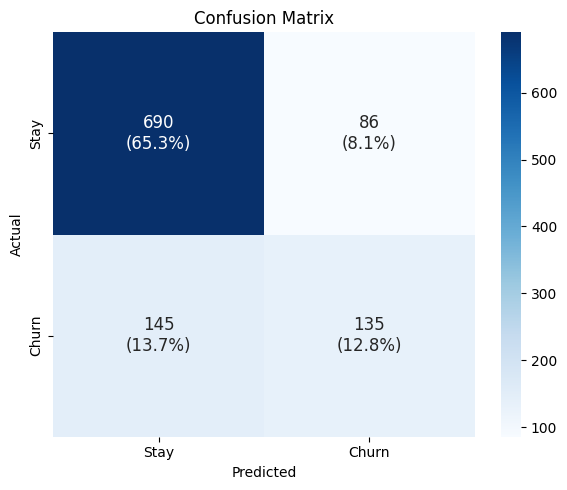

In [142]:
plot_confusion_matrix(rf_pipeline, X_val, y_val)

> With a poor recall of 47%, we need to try a weighted RF.

### Weighted RF

In [143]:
rf_balanced = build_rf_pipeline(num_features, cat_features, "balanced")

In [144]:
rf_balanced.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [145]:
# Cross validated the weighted rf model

rf_balanced_cv_results = cross_validate_model(rf_balanced, X_train, y_train)
display(rf_balanced_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.773,0.565,0.640,0.600,0.820
std,0.009,0.018,0.032,0.011,0.009


In [146]:
rf_balanced_val_perf = evaluate_model(rf_balanced, X_val, y_val)
display(rf_balanced_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.861     0.804     0.831       776
       Churn      0.541     0.639     0.586       280

    accuracy                          0.760      1056
   macro avg      0.701     0.722     0.709      1056
weighted avg      0.776     0.760     0.766      1056



Accuracy     0.760
Precision    0.541
Recall       0.639
F1           0.586
ROC-AUC      0.824
dtype: float64

> The recall for churners is at 46%. The model performance did not improve after adding class weights.


## Let's try with 'balanced_subsample' where the class_weight is computed for each tree. 

In [147]:
rf_sub = build_rf_pipeline(num_features, cat_features, "balanced_subsample")

In [148]:
rf_sub.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [149]:
# Let's get the cv scores.

rf_sub_cv_results = cross_validate_model(rf_sub, X_train, y_train)
display(rf_sub_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.792,0.643,0.485,0.552,0.821
std,0.012,0.034,0.034,0.027,0.008


In [150]:
rf_sub_val_perf = evaluate_model(rf_sub, X_val, y_val)
display(rf_sub_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.823     0.888     0.854       776
       Churn      0.603     0.471     0.529       280

    accuracy                          0.777      1056
   macro avg      0.713     0.680     0.692      1056
weighted avg      0.765     0.777     0.768      1056



Accuracy     0.777
Precision    0.603
Recall       0.471
F1           0.529
ROC-AUC      0.825
dtype: float64

Observation
---
* The recall did not improve even with class_weight as balanced_subsample where the class_weight is computed for each individual tree.
* Overall, Random Forest did not beat the baseline scores observed in Logistic Regression model. In fact, it exhibited poor performance at the default classification threshold. The model was deprioritized in favour of evaluating Gradient Boosting and CatBoost.



# Gradient Boosting

### Unweighted Gradient Boosting

In [151]:
gb_pipeline = build_gb_pipeline(num_features, cat_features)
gb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [152]:
# Get CV scores

gb_cv_results = cross_validate_model(gb_pipeline, X_train, y_train)
display(gb_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.795,0.644,0.515,0.571,0.835
std,0.012,0.033,0.037,0.027,0.009


* GB yielded a recall score of 51.5%. Did not beat Logistic Regression.  

In [153]:
gb_val_results = evaluate_model(gb_pipeline, X_val, y_val)
display(gb_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.824     0.885     0.853       776
       Churn      0.599     0.475     0.530       280

    accuracy                          0.777      1056
   macro avg      0.711     0.680     0.692      1056
weighted avg      0.764     0.777     0.768      1056



Accuracy     0.777
Precision    0.599
Recall       0.475
F1           0.530
ROC-AUC      0.836
dtype: float64

> GB is able to distinguish between the two classes, however it is not able to identify enough churners at a threshold of 0.5

ROC-AUC of 0.836 means that if we randomly select one churner and one non-churner, the model has approximately an 83.6% chance of assigning the churner a higher score, counting ties appropriately.

## Let's check GB balanced

In [154]:
gb_balanced = build_gb_pipeline(num_features, cat_features)

In [155]:
from sklearn.utils.class_weight import compute_sample_weight

weights = compute_sample_weight(class_weight="balanced", y=y_train)

In [156]:
gb_balanced.fit(X_train, y_train, model__sample_weight=weights)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

* Since we are using stratifiedkfold, the class distribution across the folds will represent the original dataset. So it's fine to take the weights calculated for the whole trainset and use that for CV. 

In [157]:
gb_balanced_cv = cross_validate_model(
    gb_balanced, X_train, y_train, fit_params={"model__sample_weight": weights}
)
display(gb_balanced_cv)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.756,0.529,0.731,0.613,0.833
std,0.012,0.015,0.030,0.017,0.011


* The CV recall is greater by more than 20 points. Weighting has improved the CV score. 

In [158]:
gb_balanced_val_results = evaluate_model(gb_balanced, X_val, y_val)
display(gb_balanced_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.891     0.747     0.813       776
       Churn      0.516     0.746     0.610       280

    accuracy                          0.747      1056
   macro avg      0.703     0.747     0.712      1056
weighted avg      0.792     0.747     0.759      1056



Accuracy     0.747
Precision    0.516
Recall       0.746
F1           0.610
ROC-AUC      0.835
dtype: float64

* Balanced Gradient Boosting model has improved substantially, and the CV and validation results are remarkably consistent. However, it is not better than Logistic Regression yet.

Since we have more number of categorical features than numerical features, let's try out CatBoost as it handles categorical features more elegantly. 

# CatBoost

In [159]:
cb_pipeline = build_catboost_pipeline()

cb_pipeline.fit(X_train, y_train, model__cat_features=cat_features)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"


In [160]:
# let's get the CV score for unweighted catboost

cb_cv_results = cross_validate_model(
    cb_pipeline, X_train, y_train, fit_params={"model__cat_features": cat_features}
)
display(cb_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.804,0.663,0.538,0.592,0.843
std,0.013,0.036,0.056,0.036,0.011


In [161]:
cb_val_perf = evaluate_model(cb_pipeline, X_val, y_val)
display(cb_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.844     0.893     0.868       776
       Churn      0.647     0.543     0.590       280

    accuracy                          0.800      1056
   macro avg      0.745     0.718     0.729      1056
weighted avg      0.792     0.800     0.794      1056



Accuracy     0.800
Precision    0.647
Recall       0.543
F1           0.590
ROC-AUC      0.840
dtype: float64

> Unweighted catboost has poor recall for our objective, but the generalization is good. Let's weight it and try. 

## weighted catboost

In [162]:
cb_balanced = build_catboost_pipeline(auto_class_weights="Balanced")
cb_balanced.fit(X_train, y_train, model__cat_features=cat_features)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"


In [163]:
cb_balanced_cv_results = cross_validate_model(
    cb_balanced, X_train, y_train, fit_params={"model__cat_features": cat_features}
)
display(cb_balanced_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.765,0.542,0.757,0.631,0.842
std,0.013,0.018,0.033,0.012,0.010


* The CV score has improved by 25 points after weights. The model achieved a recall of 76% but still did not beat logistic regression recall of 82%!!


In [164]:
display(evaluate_model(cb_balanced, X_val, y_val))


Classification Report:
              precision    recall  f1-score   support

        Stay      0.890     0.750     0.814       776
       Churn      0.517     0.743     0.610       280

    accuracy                          0.748      1056
   macro avg      0.704     0.746     0.712      1056
weighted avg      0.791     0.748     0.760      1056



Accuracy     0.748
Precision    0.517
Recall       0.743
F1           0.610
ROC-AUC      0.837
dtype: float64

> Weighted Gradient Boosting and Weighted cat boost performs very similarly. Although, the weighted Logistic Regression still remains to be the better performer. 

# Support Vector Machines

In [165]:
svm_linear = build_svm_pipeline(num_features, cat_features)
svm_linear.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [166]:
svm_linear_cv = cross_validate_model(svm_linear, X_train, y_train)
display(svm_linear_cv)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.805,0.659,0.552,0.600,0.837
std,0.009,0.022,0.044,0.026,0.011


In [167]:
svm_linear_val_perf = evaluate_model(svm_linear, X_val, y_val)
display(svm_linear_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.843     0.885     0.864       776
       Churn      0.631     0.543     0.583       280

    accuracy                          0.795      1056
   macro avg      0.737     0.714     0.724      1056
weighted avg      0.787     0.795     0.789      1056



Accuracy     0.795
Precision    0.631
Recall       0.543
F1           0.583
ROC-AUC      0.838
dtype: float64

* The recall is poor for our objective, but the model is generalising well. Let's try weighting it 

In [168]:
svm_linear_balanced = build_svm_pipeline(
    num_features, cat_features, kernel="linear", class_weight="balanced"
)

svm_linear_balanced_cv = cross_validate_model(svm_linear_balanced, X_train, y_train)

display(svm_linear_balanced_cv)

svm_linear_balanced.fit(X_train, y_train)

display(evaluate_model(svm_linear_balanced, X_val, y_val))

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.714,0.479,0.814,0.602,0.840
std,0.022,0.022,0.020,0.014,0.009



Classification Report:
              precision    recall  f1-score   support

        Stay      0.920     0.655     0.765       776
       Churn      0.468     0.843     0.602       280

    accuracy                          0.705      1056
   macro avg      0.694     0.749     0.684      1056
weighted avg      0.800     0.705     0.722      1056



Accuracy     0.705
Precision    0.468
Recall       0.843
F1           0.602
ROC-AUC      0.840
dtype: float64

## Let's try unweighted RBF SVM

In [169]:
svm_rbf = build_svm_pipeline(
    num_features, cat_features, kernel="rbf", class_weight=None
)

svm_rbf_cv = cross_validate_model(svm_rbf, X_train, y_train)

display(svm_rbf_cv)

svm_rbf.fit(X_train, y_train)

display(evaluate_model(svm_rbf, X_val, y_val))

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.80,0.667,0.495,0.568,0.80
std,0.01,0.026,0.034,0.026,0.02



Classification Report:
              precision    recall  f1-score   support

        Stay      0.829     0.898     0.862       776
       Churn      0.633     0.486     0.549       280

    accuracy                          0.789      1056
   macro avg      0.731     0.692     0.706      1056
weighted avg      0.777     0.789     0.779      1056



Accuracy     0.789
Precision    0.633
Recall       0.486
F1           0.549
ROC-AUC      0.784
dtype: float64

* Generalises well but poor recall. 

## Weighted rbf

In [170]:
svm_rbf_balanced = build_svm_pipeline(
    num_features, cat_features, kernel="rbf", class_weight="balanced"
)

svm_rbf_cv_balanced = cross_validate_model(svm_rbf, X_train, y_train)

display(svm_rbf_cv_balanced)

svm_rbf_balanced.fit(X_train, y_train)

display(evaluate_model(svm_rbf, X_val, y_val))

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.80,0.667,0.495,0.568,0.80
std,0.01,0.026,0.034,0.026,0.02



Classification Report:
              precision    recall  f1-score   support

        Stay      0.829     0.898     0.862       776
       Churn      0.633     0.486     0.549       280

    accuracy                          0.789      1056
   macro avg      0.731     0.692     0.706      1056
weighted avg      0.777     0.789     0.779      1056



Accuracy     0.789
Precision    0.633
Recall       0.486
F1           0.549
ROC-AUC      0.784
dtype: float64

* RBF performed poorly compared to weighted linear SVM. This means that the patterns are captured decently by a linear decision boundary. 

## Take-away

The ensemble methods did not demonstrate an improvement in performance for the complexity it added. This suggests that a simple linear model may adequately capture much of the signal available in the data. Do note that Ensemble methods produced a comparable ROC - AUC score, but at their default classification - the recall was simply poor. Additional tuning may alter these results. 

But- simple, decently performing, interpretable model is the best model in this case as the alternatives didn't justify the complexity it added.. Therefore, we shall tune the Log Reg model to see if the recall and F1 can be bumped up meaningfully. 

# Hyperparamter tuning with Optuna

In [171]:
from sklearn.metrics import make_scorer, fbeta_score

f2_scorer = make_scorer(fbeta_score, beta=2)

In [172]:
def objective(trial):

    C = trial.suggest_float("C", 0.001, 100, log=True)
    # Optuna search space for l1_ratio and class_weight
    l1_ratio = trial.suggest_categorical("l1_ratio", [0.0, 1.0])
    class_weight = trial.suggest_categorical("class_weight", [None, "balanced"])

    model = build_lr_pipeline(
        num_features,
        cat_features,
        C=C,
        l1_ratio=l1_ratio,
        class_weight=class_weight,
        solver="saga",
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=f2_scorer,  # recall gets 4x weight of precision
    )

    return scores.mean()

In [195]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=25)

print("Best CV F2:", round(study.best_value, 3))
print("Best parameters:", study.best_params)

Best CV F2: 0.725
Best parameters: {'C': 8.876164423015625, 'l1_ratio': 0.0, 'class_weight': 'balanced'}


In [196]:
best_lr = build_lr_pipeline(
    num_features,
    cat_features,
    C=study.best_params["C"],
    l1_ratio=study.best_params["l1_ratio"],
    class_weight=study.best_params["class_weight"],
    solver="saga",
)

In [197]:
best_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

In [199]:
display(evaluate_model(best_lr, X_val, y_val))


Classification Report:
              precision    recall  f1-score   support

        Stay      0.915     0.736     0.816       776
       Churn      0.525     0.811     0.638       280

    accuracy                          0.756      1056
   macro avg      0.720     0.773     0.727      1056
weighted avg      0.812     0.756     0.768      1056



Accuracy     0.756
Precision    0.525
Recall       0.811
F1           0.638
ROC-AUC      0.843
dtype: float64

* Optuna has barely changed our Logistic Regression's performance.
* Logistic Regression is already capturing a substantial amount of the available predictive signal, and adjusting its regularization isn't producing meaningful improvements.

> Let's move to decision threshold tuning

# Decision threshold tuning 

In [177]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# One estimated churn probabilty for a training observation, generated without training on that observation
oof_probs = cross_val_predict(best_lr, X_train, y_train, cv=cv, method="predict_proba")[
    :, 1
]

In [178]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

In [179]:
threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.01):

    y_pred = (oof_probs >= threshold).astype(int)

    threshold_results.append(
        {
            "threshold": round(threshold, 2),
            "precision": precision_score(y_train, y_pred, zero_division=0),
            "recall": recall_score(y_train, y_pred, zero_division=0),
            "f1": f1_score(y_train, y_pred, zero_division=0),
            "f2": fbeta_score(y_train, y_pred, beta=2, zero_division=0),
        }
    )

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(["precision"], ascending=False).tail(20)

,threshold,precision,recall,f1,f2
19,0.39,0.459200,0.877676,0.602941,0.742369
18,0.38,0.455224,0.886086,0.601453,0.745050
17,0.37,0.452640,0.891437,0.600412,0.746670
16,0.36,0.448527,0.896024,0.597807,0.746973
15,0.35,0.442728,0.898318,0.593135,0.744991
14,0.34,0.438499,0.902141,0.590148,0.744667
13,0.33,0.434162,0.907492,0.587333,0.745041
12,0.32,0.430997,0.912080,0.585378,0.745625
11,0.31,0.428011,0.918196,0.583860,0.747076
10,0.30,0.425300,0.922783,0.582248,0.747831


In [180]:
chosen_threshold = 0.37

val_probs = best_lr.predict_proba(X_val)[:, 1]
val_pred = (val_probs >= chosen_threshold).astype(int)

print(classification_report(y_val, val_pred, target_names=["Stay", "Churn"], digits=3))

print("Validation F2:", round(fbeta_score(y_val, val_pred, beta=2), 3))

              precision    recall  f1-score   support

        Stay      0.953     0.595     0.733       776
       Churn      0.450     0.918     0.604       280

    accuracy                          0.681      1056
   macro avg      0.701     0.757     0.668      1056
weighted avg      0.819     0.681     0.699      1056

Validation F2: 0.76


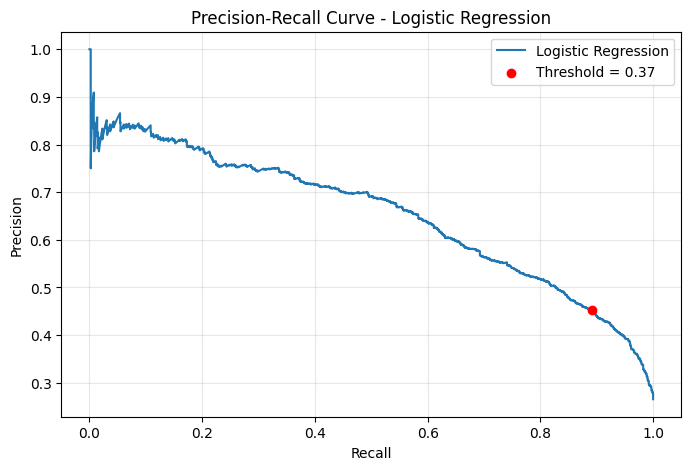

In [181]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(y_train, oof_probs)

plt.figure(figsize=(8, 5))

plt.plot(recall, precision, label="Logistic Regression")

plt.scatter(
    threshold_df.loc[threshold_df["threshold"] == 0.37, "recall"],
    threshold_df.loc[threshold_df["threshold"] == 0.37, "precision"],
    label="Threshold = 0.37",
    color="red",
    zorder=5,
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

* If we try to pick a threshold that gives good recall, then we are at the risk of false positives. It is observed that, at a decision threshold of 0.37 - the recall is 91.8% and precision is 45%. At this precision, if the model flags 100 customers as churners, then only 45 are correct (match the reality). This means, the model flagged 55 customers as churners incorrectly. Instead of trying to get one best threshold, let's perform **Risk Stratification** so that, we can divide the flagged customers into segments of high to low risk based on which the retention efforts can be decided. 

# Feature Engineering to check if LR performance improves

we shall introduce tenure x monthly charges for interactions and tenure squared (non-linear term)

In [182]:
lr_features = build_lr_feature_pipeline(num_features, cat_features, "balanced")

In [183]:
# Cross validate

lr_features_cv_results = cross_validate_model(lr_features, X_train, y_train)
display(lr_features_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.749,0.518,0.791,0.626,0.846
std,0.013,0.016,0.025,0.016,0.009


In [184]:
# Validation performance

lr_features.fit(X_train, y_train)
lr_feature_val_perf = evaluate_model(lr_features, X_val, y_val)
display(lr_feature_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.909     0.732     0.811       776
       Churn      0.517     0.796     0.627       280

    accuracy                          0.749      1056
   macro avg      0.713     0.764     0.719      1056
weighted avg      0.805     0.749     0.762      1056



Accuracy     0.749
Precision    0.517
Recall       0.796
F1           0.627
ROC-AUC      0.847
dtype: float64

> engineered features may have helped the model rank customers slightly better, but they haven't improved our preferred classification metrics.
> Note that the feature engineered model used same config as the balanced log reg model.


### The current flow goes on like this:

1. Validated weighted and unweighted models: weighted models showed significant improvement in performance.
2. We tried Hyperparameter tuning with optuna and learned that the default configuration was already at its best. The tuned parameters improved the performance barely.
3. Since the performance observed was at the default threshold, we tried tuning the threshold in hopes of seeing better performance. While the threshold of 0.37 yields a promising recall, reducing the threshold hurt precision too much. Tuning for a single best threshold was observed to be inadequate. Risk Stratification could be an operationally better approach.
4. As a last attempt, feature engineered the model at default settings and balancing the class weights, introducing an interaction term(tenure x monthly charges) and a non linear term (tenure squared). The model performed slightly worse. It was learnt that engineered features did not demonstrate sufficient improvement in the performance. 

# Retention Strategy using Model's Churn scores

We shall do so, by trying to answer these questions.

1. Caliberation : Can we trust the predicted probabilities?
2. Risk Stratification: How should we group customers based on risk tiers using risk rankings ?
3. Operational Strategy: Which interventions are appropriate for each tier, considering cost and bandwidth ? 

## Calibration Curve
We shall divide the customers into 10 bins and compare their average predicted churn probability with their actual churn rate.  

For each bin it calculates, Observed Churn rate - Mean predicted probability.

In [185]:
lr_final = build_lr_pipeline(num_features, cat_features, class_weight="balanced")
display(lr_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.

In [186]:
lr_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using 

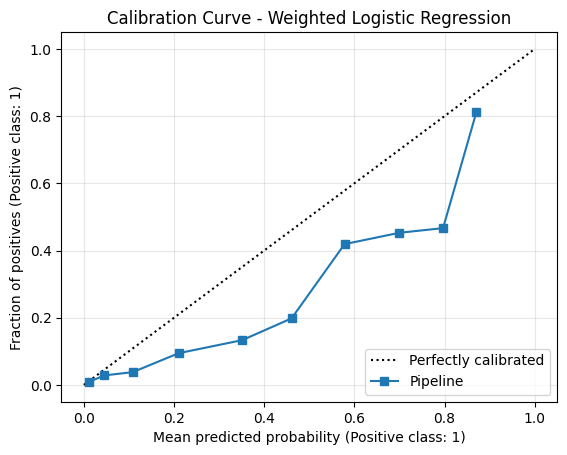

Brier score: 0.167


In [187]:
CalibrationDisplay.from_estimator(
    lr_final, X_val, y_val, n_bins=10, strategy="quantile"
)

plt.title("Calibration Curve - Weighted Logistic Regression")
plt.grid(alpha=0.3)
plt.show()

val_probs = lr_final.predict_proba(X_val)[:, 1]

print("Brier score:", round(brier_score_loss(y_val, val_probs), 4))

* The weighted Logistic Regression model is overestimating the churn probabilities. Predicted probability is higher than the observed churn frequency (the blue line -observed reality is below the dotted line -theoritical ideal y=x). Think of it like a thermometer which reads hotter than the actual temperature.
* This could be possible because we weighted the classes.
* So, our model's churn probability should be be interpreted literally indicating that we need to caliberate the model - try to bring the blue line closer to the dotted line.

# Calibrating the model

* The churn probabilities produced by our model is exaggerating the risk of churn. We shall use caliberator as a translator, that tones down the probability to make it more realistic.
* We shall use try out two methods and pick the one that performs well.
  1. Sigmoid Platt - Learns smooth logistic mapping from scores to probabilities
  2. Isotonic - Learns a flexible monotonic mapping

The Reliability diagram is a visual representation of the calibration and the Brier score tells us the overall accuracy of the probabilities (0 to 1: 0 = flawless, 1 = worst)

In [188]:
# 1. Sigmoid Platt

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_calibrated = CalibratedClassifierCV(
    lr_final, method="sigmoid", cv=cv, ensemble=False
)
"""
ensemble = False does the following:

1. Generates out-of-fold predictions on the training data.
2. Uses those predictions and actual outcomes to learn a calibration mapping.
3. Fits the underlying Logistic Regression pipeline on the full training set.
4. Applies the learned calibration mapping to its scores.

"""

'\nensemble = False does the following:\n\n1. Generates out-of-fold predictions on the training data.\n2. Uses those predictions and actual outcomes to learn a calibration mapping.\n3. Fits the underlying Logistic Regression pipeline on the full training set.\n4. Applies the learned calibration mapping to its scores.\n\n'

In [189]:
lr_calibrated.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...m_state=42))])
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn

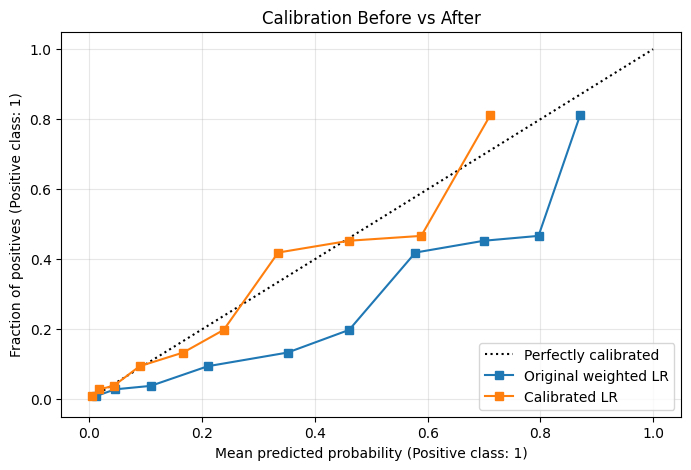

In [190]:
fig, ax = plt.subplots(figsize=(8, 5))

CalibrationDisplay.from_estimator(
    lr_final,
    X_val,
    y_val,
    n_bins=10,
    strategy="quantile",
    name="Original weighted LR",
    ax=ax,
)

CalibrationDisplay.from_estimator(
    lr_calibrated,
    X_val,
    y_val,
    n_bins=10,
    strategy="quantile",
    name="Calibrated LR",
    ax=ax,
)

plt.title("Calibration Before vs After")
plt.grid(alpha=0.3)
plt.show()

In [191]:
original_probs = lr_final.predict_proba(X_val)[:, 1]
calibrated_probs = lr_calibrated.predict_proba(X_val)[:, 1]

print("Original Brier:", round(brier_score_loss(y_val, original_probs), 4))

print("Calibrated Brier:", round(brier_score_loss(y_val, calibrated_probs), 4))

Original Brier: 0.167
Calibrated Brier: 0.1369


In [192]:
(
    brier_score_loss(y_val, calibrated_probs) - brier_score_loss(y_val, original_probs)
) / brier_score_loss(y_val, original_probs)

-0.1806645715957928

NOTES
---
* We have achieved an decent reduction(18%) in the Brier score indicating substantial improvement. However, the calibrated curved fluctuates especially in the middle. 

In [193]:
# Isotonic Calibration
lr_isotonic = CalibratedClassifierCV(
    estimator=lr_final, method="isotonic", cv=cv, ensemble=False
)

lr_isotonic.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...m_state=42))])
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklear

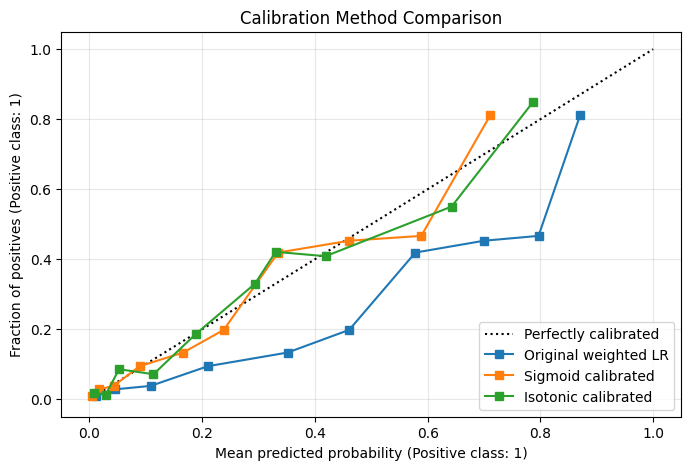

Original weighted LR: 0.1670
Sigmoid calibrated: 0.1369
Isotonic calibrated: 0.1372


In [194]:
fig, ax = plt.subplots(figsize=(8, 5))

models = {
    "Original weighted LR": lr_final,
    "Sigmoid calibrated": lr_calibrated,
    "Isotonic calibrated": lr_isotonic,
}

for name, model in models.items():
    CalibrationDisplay.from_estimator(
        model, X_val, y_val, n_bins=10, strategy="quantile", name=name, ax=ax
    )

plt.title("Calibration Method Comparison")
plt.grid(alpha=0.3)
plt.show()

for name, model in models.items():
    probs = model.predict_proba(X_val)[:, 1]
    score = brier_score_loss(y_val, probs)
    print(f"{name}: {score:.4f}")

Observation
---
* Owing to the slightly better Brier score and simpler transformation, we will use the model that's calibrated with sigmoid method.

## Expected Calibration Curve (ECE)
Takes the weighted average for all the bins (as seen in calibration curve)

In [210]:
y_prob = lr_calibrated.predict_proba(X_val)[:, 1]

ece, bin_summary = calculate_ece(y_val, y_prob, n_bins=10)

print("Expected Calibration Error (ECE):", round(ece, 4))
print(bin_summary)

Expected Calibration Error (ECE): 0.0271
               customers  observed_rate  mean_probability  calibration_gap
bin                                                                       
(-0.001, 0.1]        390       0.038462          0.032374         0.006087
(0.1, 0.2]           124       0.112903          0.146958         0.034055
(0.2, 0.3]           147       0.272109          0.243918         0.028191
(0.3, 0.4]            79       0.367089          0.352103         0.014986
(0.4, 0.5]            81       0.444444          0.445473         0.001029
(0.5, 0.6]            87       0.494253          0.553421         0.059168
(0.6, 0.7]            91       0.593407          0.647559         0.054153
(0.7, 0.8]            54       0.851852          0.742114         0.109738
(0.8, 0.9]             3       1.000000          0.802964         0.197036


In [214]:
# unit test to check if ece function is working correctly
y_true = [0, 0, 1, 1]
y_prob = [0.0, 0.0, 1.0, 1.0]

ece, _ = calculate_ece(y_true, y_prob)

assert np.isclose(ece, 0.0)

## Observations

* The model has an ECE of 2.71%, which is the weighted average absolute calibration gap across the probability bins. 

* The calibration gap for the probability bin 0% to 10% is approximately 0.6 percentage points. This shows that the observed churn rate and predicted probability are closely aligned in this range on the validation set. Similarly, the calibration gap in the 40% to 50% range is approximately 0.1 percentage points, suggesting good calibration in this bin.

* In the 70% to 80% and 80% to 90% bins, the calibration gaps are approximately 11 and 19.7 percentage points, respectively. In both bins, the observed churn rate is higher than the predicted probability, suggesting possible underestimation of churn risk. However, these bins contain only 54 and 3 customers, respectively. The estimates are subject to sampling uncertainty, particularly in the 80% to 90% bin, where the sample size is extremely small. Therefore, we should avoid drawing strong conclusions about systematic underestimation from these results alone.

ECE weights each bin by its customer count so the model is able to achieve a lower EC even when some smaller high-risk segments have relatively large calibration gaps 

## Comparison of calibrated models with weight LR model

In [217]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

models = {
    "Weighted LR": lr_final,
    "Sigmoid Calibrated LR": lr_calibrated,
    "Isotonic Calibrated LR": lr_isotonic,
}

results = []

for name, model in models.items():

    y_prob = model.predict_proba(X_val)[:, 1]
    ece, _ = calculate_ece(y_val, y_prob)

    results.append(
        {
            "Model": name,
            "Brier Score": round(brier_score_loss(y_val, y_prob), 3),
            "log loss": round(log_loss(y_val, y_prob), 3),
            "ROC AUC": round(roc_auc_score(y_val, y_prob), 3),
        }
    )

calibration_results = pd.DataFrame(results)

display(calibration_results)

,Model,Brier Score,log loss,ROC AUC
0,Weighted LR,0.167,0.493,0.843
1,Sigmoid Calibrated LR,0.137,0.419,0.843
2,Isotonic Calibrated LR,0.137,0.418,0.843


Observation and conclusion
---
> All three models have comparable ROC AUC and the Brier score improved in both the calibrated models. However, the isotonic-calibrated model performs marginally better than the sigmoid-calibrated model, but the sigmoid-calibrated model will be selected as our final model because it uses a simpler parametric mapping. 

# Risk Stratification using Sigmoid Calibrated Model

We will use the sigmoid calibrated probabilities to assign the customers to Low, Medium and High Risk tiers. Subsequently apply our EDA findings: Strong association of tenure with churn risk and moderately strong association of Contract type with churn risk - to segment customers within these risk tiers to tailor retention strategies. 

Example: customer with 75% risk of churn and tenure of 15months does not require the same retention strategy as a customer with a same risk of churn but a tenure of 1 month. 

In [225]:
segment_df = X_val[["tenure", "Contract"]].copy()

segment_df["actual_churn"] = y_val

segment_df["predicted_churn"] = lr_calibrated.predict_proba(X_val)[:, 1]

segment_df["tenure_group"] = pd.cut(
    segment_df["tenure"],
    bins=[-1, 6, 12, 24, float(np.inf)],
    labels=["0-6 months", "6-12 months", "12-24 months", "24+ months"],
)

segment_summary = segment_df.groupby("tenure_group", observed=True).agg(
    customers=("actual_churn", "size"),
    observed_churn_rate=("actual_churn", "mean"),
    mean_predicted_churn_rate=("predicted_churn", "mean"),
)

display(segment_summary)

,customers,observed_churn_rate,mean_predicted_churn_rate
tenure_group,,,
0-6 months,234,0.487179,0.464400
6-12 months,109,0.440367,0.443098
12-24 months,147,0.231293,0.331938
24+ months,566,0.148410,0.131450


In [227]:
segment_df.groupby("Contract", observed=True).agg(
    customers=("actual_churn", "size"),
    observed_churn_rate=("actual_churn", "mean"),
    mean_predicted_churn_rate=("predicted_churn", "mean"),
)

,customers,observed_churn_rate,mean_predicted_churn_rate
Contract,,,
Month-to-month,585,0.427350,0.425545
One year,222,0.121622,0.108559
Two year,249,0.012048,0.028589


In [231]:
join_summary = segment_df.groupby(["tenure_group", "Contract"], observed=True).agg(
    customers=("actual_churn", "size"),
    observed_churn_rate=("actual_churn", "mean"),
    mean_predicted_churn_rate=("predicted_churn", "mean"),
)
display(join_summary.round(3))

customers  observed_churn_rate  \
tenure_group Contract                                         
0-6 months   Month-to-month        224                0.504   
             One year                7                0.143   
             Two year                3                0.000   
6-12 months  Month-to-month         89                0.506   
             One year               16                0.188   
             Two year                4                0.000   
12-24 months Month-to-month        104                0.308   
             One year               27                0.074   
             Two year               16                0.000   
24+ months   Month-to-month        168                0.357   
             One year              172                0.122   
             Two year              226                0.013   

                             mean_predicted_churn_rate  
tenure_group Contract                                   
0-6 months   Month-to-month                      0.479  
             One year                            0.157  
             Two year                            0.072  
6-12 months  Month-to-month                      0.505  
             One year                            0.193  
             Two year                            0.060  
12-24 months Month-to-month                      0.436  
             One year                            0.101  
             Two year                            0.047  
24+ months   Month-to-month                      0.305  
             One year                            0.100  
             Two year                            0.026

The contract type distinguishes the customers across all the tenure groups. The month-to-month contract type, especially, has the highest observation rate compared to the rest of the contract types within these groups. The 2-year contract type in each of the senior groups has a very low churn rate. Interestingly, customers who spent 0 to 12 months in the system and have a contract type of 2 years have a 0% observed churn rate. This suggests that the contract type and the tenure group must be accounted for while deciding on operational strategies for retention.

The model is overestimating the churn rate for the tenure group of 12 to 24 months with a month-to-month contract type. This suggests that even though the model has an overall lower EC, the calibrated probability for this specific group is not reliable. The general suggestion would be that this group can be monitored at a low level, depending on the individual churn risk of the customer.

The customers with a tenure of more than 24 months do have an observed churn of 35% from the month-to-month contract. This implies that customers who stay longer in the system do not escape the risk of churning, and customers with a month-to-month contract can always churn. Customers with a month-to-month contract always do have the potential to churn, so this group needs to be addressed with respect to service issues and renewals. 

In [234]:
risk_distribution = segment_df["predicted_churn"].describe(
    percentiles=[0.10, 0.3, 0.50, 0.75, 0.90, 0.95]
)

display(risk_distribution)

count    1056.000000
mean        0.265306
std         0.239880
min         0.001251
10%         0.009958
30%         0.061998
50%         0.210868
75%         0.458976
90%         0.643640
95%         0.703970
max         0.804422
Name: predicted_churn, dtype: float64

In [248]:
# Let's see how many customers are predicted to churn at different thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_summary = pd.DataFrame(
    {
        "thresholds": thresholds,
        "customers": [(segment_df["predicted_churn"] >= t).sum() for t in thresholds],
    }
)

threshold_summary["population_share %"] = 100.0 * (
    threshold_summary["customers"] / len(segment_df)
).round(2)
display(threshold_summary)

,thresholds,customers,population_share %
0,0.3,395,37.0
1,0.4,316,30.0
2,0.5,235,22.0
3,0.6,148,14.0
4,0.7,57,5.0


In [253]:
# How effectively would we identify churners at different thresholds?
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

overall_churn_rate = segment_df["actual_churn"].mean()

results = []

for threshold in thresholds:
    y_pred = (segment_df["predicted_churn"] >= threshold).astype(int)

    results.append(
        {
            "threshold": threshold,
            "customers": y_pred.sum(),
            "precision": precision_score(
                segment_df["actual_churn"], y_pred, zero_division=0
            ),
            "recall": recall_score(segment_df["actual_churn"], y_pred, zero_division=0),
        }
    )


threshold_perf = pd.DataFrame(results)

# Lift measures how much better we are at identifying churners compared to random selection.
# A lift of 2 means we are twice as effective as random selection.

threshold_perf["lift"] = (threshold_perf["precision"] / overall_churn_rate).round(2)

display(threshold_perf.round(2))

,threshold,customers,precision,recall,lift
0,0.3,395,0.53,0.75,2.01
1,0.4,316,0.58,0.65,2.17
2,0.5,235,0.62,0.52,2.34
3,0.6,148,0.70,0.37,2.62
4,0.7,57,0.86,0.18,3.24


* The lift at the threshold of 0.7 is 3.24 which means the model is 3.24 times effective at identifying churners than random guessing at this specific threshold. However, this does not mean high lift simply qualifies this threshold to make business decisions as the model is showing poor recall at this threshold. 
* Combining the risk tiers along with Contract, tenure and monthly charges will be a better approach in order to devise retention strategies. 

In [257]:
segment_df["risk_tier"] = segment_df["predicted_churn"].apply(assign_risk_tier)

segment_df.groupby("risk_tier", observed=True).size().reset_index(
    name="customers"
).sort_values("risk_tier")

,risk_tier,customers
0,High Risk,178
1,Low Risk,661
2,Medium Risk,160
3,Very High Risk,57


In [268]:
overall_churn_rate = segment_df["actual_churn"].mean()

tier_summary = segment_df.groupby("risk_tier", observed=True).agg(
    customers=("actual_churn", "size"),
    churners=("actual_churn", "sum"),
    observed_churn_rate=("actual_churn", "mean"),
    mean_predicted_churn_rate=("predicted_churn", "mean"),
)

tier_summary["population_share %"] = 100.0 * (
    tier_summary["customers"] / len(segment_df)
).round(2)

tier_summary["churn_capture_pct"] = (
    100 * tier_summary["churners"] / segment_df["actual_churn"].sum()
)

tier_summary["Lift"] = (tier_summary["observed_churn_rate"] / overall_churn_rate).round(
    2
)

display(tier_summary)

,customers,churners,observed_churn_rate,mean_predicted_churn_rate,population_share %,churn_capture_pct,Lift
risk_tier,,,,,,,
High Risk,178,97,0.544944,0.601548,17.0,34.642857,2.06
Low Risk,661,69,0.104387,0.100915,63.0,24.642857,0.39
Medium Risk,160,65,0.406250,0.399372,15.0,23.214286,1.53
Very High Risk,57,49,0.859649,0.745316,5.0,17.500000,3.24


* NOTE: The lift in low risk segment is < 1, exactly what we want because the model cannot identify churners in a segment where churn is less common than average. 
* 52% of the churners are captured in High Risk and Very High Risk tiers

In [269]:
tier_summary["churn_capture_pct"].sum()

np.float64(100.0)

In [271]:
priority_summary = (
    segment_df[segment_df["risk_tier"].isin(["High Risk", "Very High Risk"])]
    .groupby("risk_tier", observed=True)
    .agg(
        customers=("actual_churn", "size"),
        churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_churn_rate=("predicted_churn", "mean"),
    )
)

display(priority_summary.round(2))

,customers,churners,observed_churn_rate,mean_predicted_churn_rate
risk_tier,,,,
High Risk,178,97,0.54,0.60
Very High Risk,57,49,0.86,0.75


In [272]:
priority_customers = segment_df[
    segment_df["risk_tier"].isin(["High Risk", "Very High Risk"])
].copy()

priority_summary = (
    priority_customers.groupby(["risk_tier", "tenure_group", "Contract"], observed=True)
    .agg(
        customers=("actual_churn", "size"),
        churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_churn_rate=("predicted_churn", "mean"),
    )
    .reset_index()
)

display(priority_summary.round(3))

,risk_tier,tenure_group,Contract,customers,churners,observed_churn_rate,mean_predicted_churn_rate
0,High Risk,0-6 months,Month-to-month,78,48,0.615,0.618
1,High Risk,6-12 months,Month-to-month,33,20,0.606,0.595
2,High Risk,12-24 months,Month-to-month,42,16,0.381,0.583
3,High Risk,24+ months,Month-to-month,25,13,0.520,0.592
4,Very High Risk,0-6 months,Month-to-month,33,28,0.848,0.743
5,Very High Risk,6-12 months,Month-to-month,18,16,0.889,0.752
6,Very High Risk,12-24 months,Month-to-month,6,5,0.833,0.739


In [275]:
assert priority_summary["customers"].sum() == 235
assert priority_summary["churners"].sum() == 146

In [ ]:
# Let's add one more layer to improve the priority assigment
# Getting the 25th and 75th percentiles of MonthlyCharges to create a new feature for risk stratification, apply this to val set.

q25 = X_train["MonthlyCharges"].quantile(0.25)
q75 = X_train["MonthlyCharges"].quantile(0.75)

print(f"25th percentile: {q25:.2f}")
print(f"75th percentile: {q75:.2f}")

25th percentile: 35.82
75th percentile: 90.04


In [279]:
segment_df["revenue_segment"] = pd.cut(
    X_val["MonthlyCharges"],
    bins=[-1, q25, q75, float("inf")],
    labels=["Low", "Middle", "Higher"],
)
segment_df.head()

,tenure,Contract,actual_churn,predicted_churn,tenure_group,risk_tier,revenue_segment
5960,62,One year,0,0.155861,24+ months,Low Risk,Middle
1266,4,Month-to-month,0,0.669815,0-6 months,High Risk,Middle
3177,72,Two year,0,0.006447,24+ months,Low Risk,Middle
36,5,Month-to-month,1,0.655557,0-6 months,High Risk,Middle
1206,3,Month-to-month,0,0.669085,0-6 months,High Risk,Middle


In [281]:
segment_df.groupby("revenue_segment", observed=True).size()

revenue_segment
Low       279
Middle    545
Higher    232
dtype: int64

In [282]:
priority_customers = segment_df[
    segment_df["risk_tier"].isin(["High Risk", "Very High Risk"])
].copy()

priority_summary = (
    priority_customers.groupby(
        ["risk_tier", "tenure_group", "Contract", "revenue_segment"], observed=True
    )
    .agg(
        customers=("actual_churn", "size"),
        churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_churn_rate=("predicted_churn", "mean"),
    )
    .reset_index()
)

display(priority_summary.round(3))

,risk_tier,tenure_group,Contract,revenue_segment,customers,churners,observed_churn_rate,mean_predicted_churn_rate
0,High Risk,0-6 months,Month-to-month,Low,10,3,0.300,0.598
1,High Risk,0-6 months,Month-to-month,Middle,65,45,0.692,0.623
2,High Risk,0-6 months,Month-to-month,Higher,3,0,0.000,0.571
3,High Risk,6-12 months,Month-to-month,Middle,27,15,0.556,0.588
4,High Risk,6-12 months,Month-to-month,Higher,6,5,0.833,0.624
5,High Risk,12-24 months,Month-to-month,Middle,27,8,0.296,0.568
6,High Risk,12-24 months,Month-to-month,Higher,15,8,0.533,0.609
7,High Risk,24+ months,Month-to-month,Middle,3,2,0.667,0.528
8,High Risk,24+ months,Month-to-month,Higher,22,11,0.500,0.600
9,Very High Risk,0-6 months,Month-to-month,Middle,28,23,0.821,0.738


In [284]:
segment_df["MonthlyCharges"] = X_val["MonthlyCharges"]

In [286]:
revenue_priority_summary = (
    segment_df.groupby(["risk_tier", "revenue_segment"], observed=True)
    .agg(
        customers=("actual_churn", "size"),
        churners=("actual_churn", "sum"),
        total_monthly_charges=("MonthlyCharges", "sum"),
        average_monthly_charges=("MonthlyCharges", "mean"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_churn_rate=("predicted_churn", "mean"),
    )
    .reset_index()
)

display(revenue_priority_summary.round(2))

,risk_tier,revenue_segment,customers,churners,total_monthly_charges,average_monthly_charges,observed_churn_rate,mean_predicted_churn_rate
0,High Risk,Low,10,3,275.45,27.54,0.30,0.60
1,High Risk,Middle,122,70,9113.20,74.70,0.57,0.60
2,High Risk,Higher,46,24,4505.75,97.95,0.52,0.60
3,Low Risk,Low,255,19,5533.30,21.70,0.07,0.08
4,Low Risk,Middle,293,33,19778.30,67.50,0.11,0.11
5,Low Risk,Higher,113,17,11463.10,101.44,0.15,0.14
6,Medium Risk,Low,14,4,387.50,27.68,0.29,0.39
7,Medium Risk,Middle,96,36,5814.75,60.57,0.38,0.40
8,Medium Risk,Higher,50,25,4955.00,99.10,0.50,0.40
9,Very High Risk,Middle,34,27,2682.30,78.89,0.79,0.74


In [288]:
# This will help us compare potential monthly billing exposure across tiers rather than simply prioritizing whoever pays the most
segment_df["risk_weighted_billing"] = (
    segment_df["predicted_churn"] * segment_df["MonthlyCharges"]
)

revenue_risk_summary = segment_df.groupby("risk_tier", observed=True).agg(
    customers=("actual_churn", "size"),
    total_monthly_charges=("MonthlyCharges", "sum"),
    risk_weighted_billing=("risk_weighted_billing", "sum"),
)

display(revenue_risk_summary.round(2))

,customers,total_monthly_charges,risk_weighted_billing
risk_tier,,,
High Risk,178,13894.40,8372.19
Low Risk,661,36774.70,4076.95
Medium Risk,160,11157.25,4477.08
Very High Risk,57,4917.75,3672.19


High Risk customers account for the largest exposure for immediate priority. 

All 235 customers in the High risk and Very High risk tier have Month-to-month contract and 162 customers out of these priority customers belong to 0-12 month tenure group. These 162 customers account for 146 churners within the priority population. 

The High risk group with tenure 12-24 months have an overestimated predicted probably - implying that individual calibrated probabilities in this group must be interpreted with caution (despite the overall encouraging ECE).

The following operational priorities may be considered:

1. Very High Risk + Month-to-month contract : P1  
    Individual retention review, addressing service concerns and intervention wherever feasible
2. High Risk + tenure <= 12 months: P2  
    Focus on customer experience during early tenure, targeted engagement
3. High Risk + tenure > 12 months: P3  
    Review service experience, contract renewals, intervention wherever feasible. 
4. Medium Risk: P4  
    Lower cost retention workflow

## How to select customers when Retention capacity is limited ?

Let's compare two methods to select customers when retention capacity is limited. 

Method A: Rank customers by probability alone
Method B: Rank customers by risk-weighted monthly charges

Questions to ask: 

1. How many churners does each method identify?
2. What total monthly charges do the selected customers represent?
3. What is the risk-weighthed billing of the selected customers?
4. How much do both methods overlap ?

In [320]:
# Let's assume the retention team has the capacity to address 100 customers only
# Ranking risk by predicted churn probability
top100_risk = segment_df.sort_values(by="predicted_churn", ascending=False).head(100)

top100_risk.head(10)

,tenure,Contract,actual_churn,predicted_churn,tenure_group,risk_tier,revenue_segment,MonthlyCharges,risk_weighted_billing
2631,7,Month-to-month,1,0.804422,6-12 months,Very High Risk,Higher,99.25,79.838900
5783,1,Month-to-month,1,0.804092,0-6 months,Very High Risk,Middle,89.30,71.805448
6365,7,Month-to-month,1,0.800377,6-12 months,Very High Risk,Higher,101.95,81.598478
6215,6,Month-to-month,1,0.794424,0-6 months,Very High Risk,Higher,98.25,78.052138
2955,7,Month-to-month,1,0.783380,6-12 months,Very High Risk,Higher,93.85,73.520184
2397,1,Month-to-month,1,0.781680,0-6 months,Very High Risk,Middle,88.35,69.061400
5,8,Month-to-month,1,0.775796,6-12 months,Very High Risk,Higher,99.65,77.308042
6626,6,Month-to-month,1,0.771651,0-6 months,Very High Risk,Higher,95.75,73.885587
1651,1,Month-to-month,1,0.771052,0-6 months,Very High Risk,Middle,79.10,60.990222
4150,7,Month-to-month,0,0.769631,6-12 months,Very High Risk,Middle,89.00,68.497176


In [319]:
# Ranking by potential revenue loss

top100_revenue = segment_df.sort_values(
    by="risk_weighted_billing", ascending=False
).head(100)

top100_revenue.head(10)

,tenure,Contract,actual_churn,predicted_churn,tenure_group,risk_tier,revenue_segment,MonthlyCharges,risk_weighted_billing
6365,7,Month-to-month,1,0.800377,6-12 months,Very High Risk,Higher,101.95,81.598478
2631,7,Month-to-month,1,0.804422,6-12 months,Very High Risk,Higher,99.25,79.838900
6215,6,Month-to-month,1,0.794424,0-6 months,Very High Risk,Higher,98.25,78.052138
5,8,Month-to-month,1,0.775796,6-12 months,Very High Risk,Higher,99.65,77.308042
5874,10,Month-to-month,1,0.765687,6-12 months,Very High Risk,Higher,100.60,77.028098
3271,12,Month-to-month,1,0.758921,6-12 months,Very High Risk,Higher,101.35,76.916656
463,7,Month-to-month,1,0.760670,6-12 months,Very High Risk,Higher,99.80,75.914879
4453,10,Month-to-month,1,0.767900,6-12 months,Very High Risk,Higher,98.50,75.638177
6385,4,Month-to-month,1,0.741064,0-6 months,Very High Risk,Higher,101.70,75.366162
5231,16,Month-to-month,1,0.763141,12-24 months,Very High Risk,Higher,98.75,75.360187


In [308]:
overlap_pct = (
    100 * (top100_risk["index"].to_numpy() == top100_revenue["index"].to_numpy()).mean()
)
display(overlap_pct.round(2))

np.float64(0.0)

In [309]:
rankings = {"Churn Probability": top100_risk, "Risk-Weighted Billing": top100_revenue}

results = []

for method, selected in rankings.items():
    results.append(
        {
            "Method": method,
            "Customers": len(selected),
            "Churners": selected["actual_churn"].sum(),
            "Precision": selected["actual_churn"].mean(),
            "Monthly Charges": selected["MonthlyCharges"].sum(),
            "Risk-Weighted Billing": selected["risk_weighted_billing"].sum(),
        }
    )

ranking_comparison = pd.DataFrame(results)

display(ranking_comparison.round(4))

,Method,Customers,Churners,Precision,Monthly Charges,Risk-Weighted Billing
0,Churn Probability,100,83,0.83,8347.55,5986.3745
1,Risk-Weighted Billing,100,76,0.76,9190.45,6359.5055


In [ ]:
overlap_count = len(set(top100_risk.index) & set(top100_revenue.index)) # & performs an intersection operation here on the sets

overlap_pct = 100 * overlap_count / 100

print(f"Overlap: {overlap_count} customers ({overlap_pct:.1f}%)")

Overlap: 71 customers (71.0%)


> 71 customers overlap between the two Ranking methods.

Let's investigate the customers unique to each Method

In [325]:
assert len(top100_risk) == 100
assert len(top100_revenue) == 100

In [326]:
risk_only = top100_risk.loc[~top100_risk.index.isin(top100_revenue.index)]

billing_only = top100_revenue.loc[~top100_revenue.index.isin(top100_risk.index)]

comparison = pd.DataFrame(
    {
        "Strategy": ["Probability Only", "Billing Only"],
        "Customers": [len(risk_only), len(billing_only)],
        "Churners": [
            risk_only["actual_churn"].sum(),
            billing_only["actual_churn"].sum(),
        ],
        "Avg Probability": [
            risk_only["actual_churn"].mean(),
            billing_only["actual_churn"].mean(),
        ],
        "Avg Monthly Charges": [
            risk_only["MonthlyCharges"].mean(),
            billing_only["MonthlyCharges"].mean(),
        ],
    }
)

display(comparison.round(2))

,Strategy,Customers,Churners,Avg Probability,Avg Monthly Charges
0,Probability Only,29,22,0.76,68.39
1,Billing Only,29,15,0.52,97.46


Choosing Probability only ranking means selecting 7 more customers (compared to Billing only ranking), swapping in for customers with lower monthly charges compared to the other other group. This is a trade-off. 

The following business rules can be considered- 

1. Primary Prioritisation: Use Churn Probability to assign Risk tiers and select customers if capacity is limit
2. Secondary Prioritisation: Use Contract type and Tenure to further to decide the extent of retention review
3. Revenue Consideration: Use Monthly Charges as a tie breaker or additional context among customers with the similar risk or priority

To freeze and implement this business rule, the probability threshold of low, medium and high risk will be 0.30, 0.50 and 0.70

NOTE: An illustrave capacity of 100 customers at risk was evaluated in order to freeze the business rule.  

# Testing the Logistic Regression Calibration model

In [327]:
y_test_prob = lr_calibrated.predict_proba(X_test)[:, 1]

In [328]:
# Let's check performance at default threshold
ece, ece_summary = calculate_ece(y_test, y_test_prob)

print(f"Test ECE: {ece:.4f}")

Test ECE: 0.0225


> The test ECE is between 0.01 and 0.05 - indicating that it is well calibrated. A score of 0.02 means the predicted probabilities are off by 2% on an average.

In [334]:
display(evaluate_model(lr_calibrated, X_test, y_test))


Classification Report:
              precision    recall  f1-score   support

        Stay      0.842     0.901     0.870       776
       Churn      0.661     0.534     0.591       281

    accuracy                          0.803      1057
   macro avg      0.751     0.717     0.731      1057
weighted avg      0.794     0.803     0.796      1057



Accuracy     0.803
Precision    0.661
Recall       0.534
F1           0.591
ROC-AUC      0.846
dtype: float64

The model has a very good ROC-AUC at the default threshold. However, the low recall suggests that the model classifies several non-churners as churners. This is why we didn't not create a business rule around a single decision threshold. 

In [337]:
print("Brier Score:", brier_score_loss(y_test, y_test_prob))
print("Log loss:", log_loss(y_test, y_test_prob))

Brier Score: 0.13574102123212048
Log loss: 0.4163312953604766


In [339]:
# baseline probability from training data
y_base_prob = y_train.mean()

y_naive_prob = np.full(len(y_test), y_base_prob)

print("Naive: ", brier_score_loss(y_test, y_naive_prob))
print("Calibrated:", brier_score_loss(y_test, y_test_prob))

Naive:  0.19517253235935036
Calibrated: 0.13574102123212048


Observations:
---
1. The ROC-AUC of 0.846 on test set indicates that the model is able to distinguish the class well. The model is 84.6% likely to rank a churner above a non-churner.
2. The ECE of 0.027 indicates that an average prediction by the model is off by 2.7% compared to the ece of 2% observed in the validation set. This is a small calibration gap.
3. Brier score of 0.135 shows that the model exhibits good probabilitic accuracy. Compared to a naive baseline where the model(Naive prevalence baseline) predicts 26.5% for everyone, the calibrated model performs well showing a 30.5% reduction in the Brier Score.

In [348]:
test_df = X_test[["tenure", "Contract", "MonthlyCharges"]].copy()

test_df["actual_churn"] = y_test
test_df["predicted_churn"] = y_test_prob

test_df["risk_tier"] = assign_risk_tier(test_df["predicted_churn"])

test_tier_summary = test_df.groupby("risk_tier", observed=True).agg(
    customers=("actual_churn", "size"),
    churners=("actual_churn", "sum"),
    observed_churn_rate=("actual_churn", "mean"),
    predicted_churn_rate=("predicted_churn", "mean"),
)

test_tier_summary["churn_capture_pct"] = (
    100 * test_tier_summary["churners"] / test_tier_summary["churners"].sum()
)  # churners / total number of churners in reality

test_tier_summary["Lift"] = (
    test_tier_summary["observed_churn_rate"] / test_df["actual_churn"].mean()
)

display(test_tier_summary)

,customers,churners,observed_churn_rate,predicted_churn_rate,churn_capture_pct,Lift
risk_tier,,,,,,
Low Risk,666,70,0.105105,0.102579,24.911032,0.395360
Medium Risk,164,61,0.371951,0.398893,21.708185,1.399119
High Risk,174,106,0.609195,0.600710,37.722420,2.291529
Very High Risk,53,44,0.830189,0.745108,15.658363,3.122809


Observations:
---
1. The low risk segment is stable with nearly identical predicted churn rate in validation set and the untouched test set
2. Out of 227 customers in the high + very high risk segment, the model identifies 156 Churners which is slighlty more than half of all the churners in the test set. 
3. The model underestimates probability in by 8.5 percentage points in the Very High Risk segment. However, number of customers in this group is very less, so this is not a matter of concern. 
4. Overall, the risk stratification is behaving consistently with what was observed during validation indicating that our Segmentation generalises well. 

# Saving the fitted model

In [356]:
from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

In [357]:
model_path = model_dir / "calibrated_lr.joblib"

joblib.dump(lr_calibrated, model_path)

print(f"Model saved to: {model_path.resolve()}")

Model saved to: /Users/priyankamanoj/UniversityCourseWork/Verizon/telco_churn_pipeline/notebooks/models/calibrated_lr.joblib


In [358]:
import shutil

source = Path("models/calibrated_lr.joblib")
destination = Path("../models/calibrated_lr.joblib")

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.move(source, destination)

print(destination.resolve())

/Users/priyankamanoj/UniversityCourseWork/Verizon/telco_churn_pipeline/models/calibrated_lr.joblib


In [364]:
model = joblib.load(PROJECT_ROOT / "models" / "calibrated_lr.joblib")

print(type(model))

<class 'sklearn.calibration.CalibratedClassifierCV'>


In [370]:
pipeline = model.calibrated_classifiers_[0].estimator

print(pipeline.named_steps.keys())

dict_keys(['cleaner', 'preprocessor', 'model'])


In [371]:
print(pipeline)

Pipeline(steps=[('cleaner', TotalChargesCleaner()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
            

In [372]:
preprocessor = pipeline.named_steps["preprocessor"]

for name, transformer, columns in preprocessor.transformers_:
    print(name, columns)

num ['tenure', 'MonthlyCharges', 'TotalCharges']
cat ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [373]:
customer = pd.DataFrame(
    [
        {
            "tenure": 6,
            "MonthlyCharges": 85.50,
            "TotalCharges": "513.00",
            "gender": "Female",
            "SeniorCitizen": 0,
            "Partner": "No",
            "Dependents": "No",
            "PhoneService": "Yes",
            "MultipleLines": "No",
            "InternetService": "Fiber optic",
            "OnlineSecurity": "No",
            "OnlineBackup": "No",
            "DeviceProtection": "No",
            "TechSupport": "No",
            "StreamingTV": "Yes",
            "StreamingMovies": "Yes",
            "Contract": "Month-to-month",
            "PaperlessBilling": "Yes",
            "PaymentMethod": "Electronic check",
        }
    ]
)


from pipeline import predict_churn

results = predict_churn(customer)

print(results)

   churn_probability       risk_tier
0           0.755644  Very High Risk
